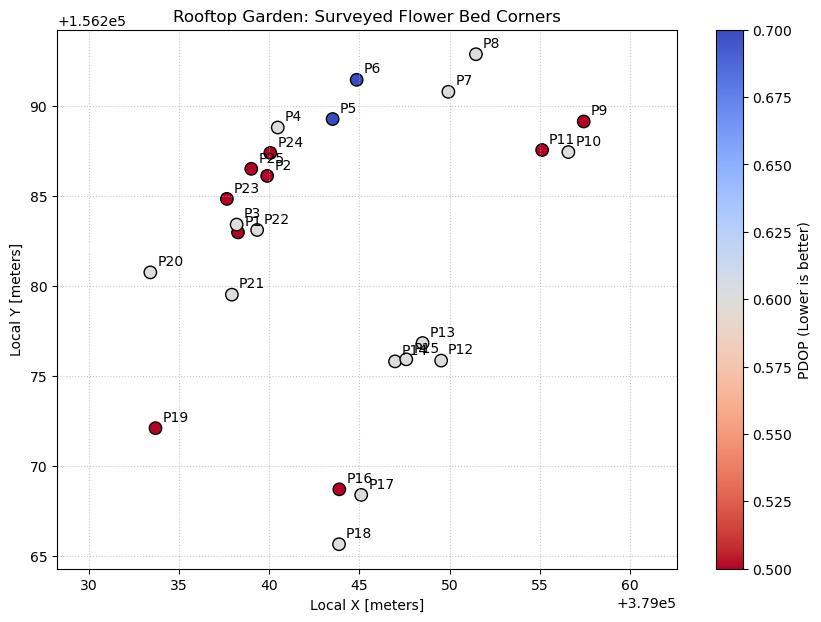

In [1]:
import os
from pathlib import Path
import pandas as pd
import matplotlib.pyplot as plt

# Resolve CSV path dynamically whether executed from repo root or module directory
csv_candidates = [
    Path('Project 1_pot_corners.csv'),
    Path('05-geospatial-satellite-telemetry') / 'Project 1_pot_corners.csv',
    Path(__file__).parent / 'Project 1_pot_corners.csv' if '__file__' in globals() else Path('Project 1_pot_corners.csv')
]

csv_path = next((p for p in csv_candidates if p.exists()), Path('Project 1_pot_corners.csv'))

try:
    # Load the survey telemetry data
    df = pd.read_csv(csv_path)
    
    # Use X and Y for a meter-based ground view (SVY21 projection)
    plt.figure(figsize=(10, 7))
    
    # Color coding by PDOP to identify satellite obstruction geometry
    scatter = plt.scatter(df['X'], df['Y'], c=df['PDOP'], cmap='coolwarm_r', s=80, edgecolors='black')
    
    # Label each pot corner ID
    for i, row in df.iterrows():
        plt.annotate(f"P{int(row['ID'])}", (row['X'], row['Y']), xytext=(5, 5), textcoords='offset points')

    plt.colorbar(scatter, label='PDOP (Lower is better)')
    plt.xlabel('Local X [meters]')
    plt.ylabel('Local Y [meters]')
    plt.title('Rooftop Garden: Surveyed Flower Bed Corners')
    plt.grid(True, linestyle=':', alpha=0.7)
    plt.axis('equal') # Prevents the garden geometry from looking stretched
    plt.show()

except FileNotFoundError:
    print(f"Error: {csv_path} not found. Please verify the survey dataset exists in 05-geospatial-satellite-telemetry.")
